# Filtre frequenciel

On condidère le signal ci dessous qui contient deux fréquences (0.1 Hz et 10 Hz). Créer un filtre pase-bas et passe-haut dans l'espace de Fourier pour isoler chaque fréquence. 
On utilisera ($f_c$ est la fréquence de coupure): 

$$H_\mathrm{LP}(f) = \frac{1}{1 + if/f_c}$$

et 

$$H_\mathrm{HP}(f) = \frac{i f/f_c}{1 + if/f_c}$$

Que se passe-t-il si on utilise $\frac{1}{1 - if/f_c}$ (on pourra regarder l'effet sur un signal carré)

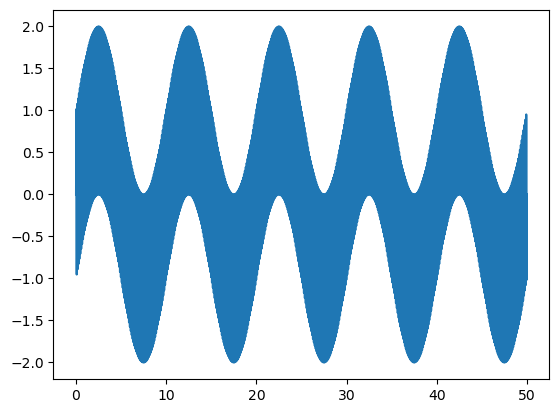

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.fft import rfft, rfftfreq, irfft

samplerate = 44100
Deltat = 1/samplerate
x = np.arange(0,50,Deltat)
freq_1 = 0.1
freq_2 = 10
signal = np.sin(2*np.pi*x*freq_1) + np.sin(2*np.pi*x*freq_2)

plt.plot(x,signal)

In [23]:
def passe_bas(signal, f_c, samplerate=44100):
    signal_tilde = rfft(signal)
    freqs = rfftfreq(len(signal), 1/samplerate)
    signal_tilde = signal_tilde /(1  + 1J*freqs/f_c)
    signal_2 = irfft(signal_tilde)
    return signal_2

def passe_haut(signal, f_c, samplerate=44100):
    signal_tilde = rfft(signal)
    freqs = rfftfreq(len(signal), 1/samplerate)
    signal_tilde = signal_tilde /(1+1J*freqs/f_c)*1J*(freqs/f_c)
    signal_2 = irfft(signal_tilde)
    return signal_2

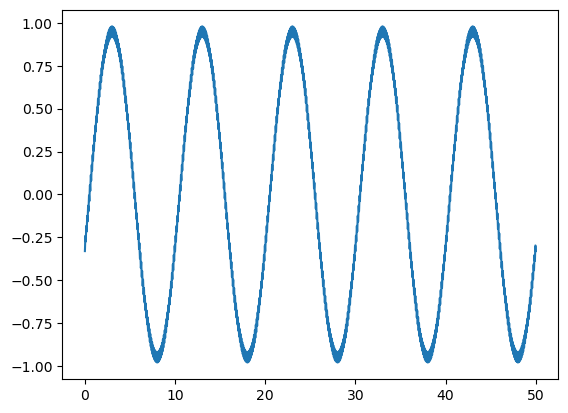

In [24]:
plt.plot(x, passe_bas(signal,0.3))

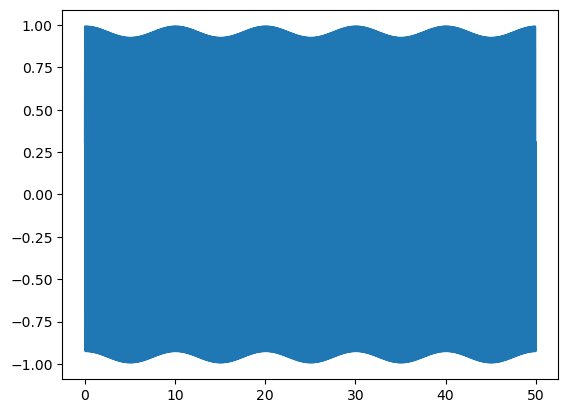

In [25]:
plt.plot(x, passe_haut(signal,3))

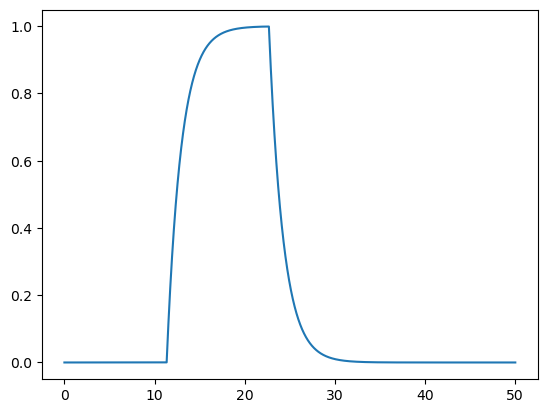

In [32]:
signal[:] = 0
signal[500_000:1000_000] = 1

plt.plot(x, passe_bas(signal,0.1))

Le filtre n'est plus causal


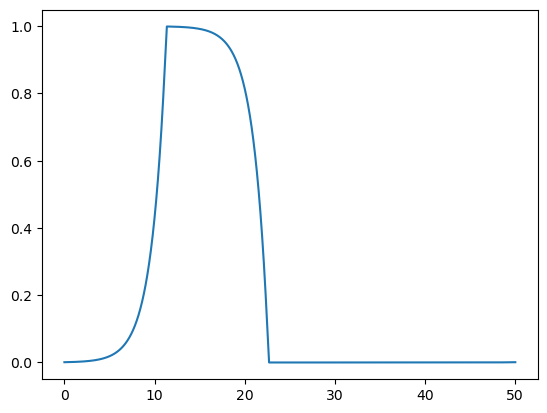

In [34]:
def passe_bas_faux(signal, f_c, samplerate=44100):
    signal_tilde = rfft(signal)
    freqs = rfftfreq(len(signal), 1/samplerate)
    signal_tilde = signal_tilde /(1  - 1J*freqs/f_c)
    signal_2 = irfft(signal_tilde)
    return signal_2

plt.plot(x, passe_bas_faux(signal,0.1))
print("Le filtre n'est plus causal")